# Commercial Fleet Route Optimization - Step 2: Classical Preprocessing
This notebook parses the SUMO network file (`osm.net.xml.gz`), builds a NetworkX directed graph restricted to roads a delivery van can use (largest strongly connected component), and computes candidate paths with Yen's $k$-shortest simple paths algorithm.

**Outputs for the QUBO step:** `paths[d]`, `C[(d,p)]` (free-flow seconds), `E[(d,p)]` (edge-ID sets), `S[(a,b)]` (shared-edge counts between routes).

In [95]:
# Install required libraries if not already installed
%pip install sumolib networkx matplotlib

Note: you may need to restart the kernel to use updated packages.


In [96]:
import os
import random
from itertools import islice, combinations

import sumolib
import networkx as nx
import matplotlib.pyplot as plt
import math

## 1. Build the road graph
Only vehicle-accessible edges are kept (`allows("delivery")`), zero-speed edges are skipped, parallel edges keep the faster one, and the graph is reduced to its largest strongly connected component so every depot→destination path exists.

In [97]:
net_path = os.path.join(os.curdir, "SUMO_GEN_SCENARIO", "osm.net.xml.gz")
assert os.path.exists(net_path), f"File not found: {net_path}"
print(f"Found network file at: {net_path}")

net = sumolib.net.readNet(net_path)

G = nx.DiGraph()
for edge in net.getEdges():
    # Skip internal junction connectors and roads a delivery van cannot drive on
    if edge.isSpecial() or not edge.allows("delivery"):
        continue
    speed = edge.getSpeed()
    if speed <= 0:
        continue

    u = edge.getFromNode().getID()
    v = edge.getToNode().getID()
    tt = edge.getLength() / speed          # free-flow travel time (s)

    # DiGraph cannot hold parallel edges: keep the faster one
    if G.has_edge(u, v) and G[u][v]["weight"] <= tt:
        continue
    G.add_edge(u, v, edge_id=edge.getID(), length=edge.getLength(), weight=tt)

print(f"Before SCC reduction: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

# Keep only the largest strongly connected component (guarantees reachability)
core = max(nx.strongly_connected_components(G), key=len)
G = G.subgraph(core).copy()

for n in G.nodes:
    G.nodes[n]["pos"] = net.getNode(n).getCoord()

print(f"Largest SCC:          {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

Found network file at: ./SUMO_GEN_SCENARIO/osm.net.xml.gz
Before SCC reduction: 5814 nodes, 14940 edges
Largest SCC:          5664 nodes, 14744 edges


## 2. Scenario configuration
Depot and destinations are sampled from the whole strongly connected component (not from file order) to avoid spatially clustered stops.

In [98]:
NUM_VANS = 3
NUM_DESTINATIONS = 3
MIN_DISTANCE = 1000  # meters

random.seed(42)

nodes = sorted(G.nodes)

# 1. Randomly select the depot
DEPOT_NODE = random.choice(nodes)

depot_x, depot_y = G.nodes[DEPOT_NODE]["pos"]

# 2. Keep nodes on the right and sufficiently far away
right_side_nodes = []

for n in nodes:
    if n == DEPOT_NODE:
        continue

    x, y = G.nodes[n]["pos"]

    # Check right-hand side
    if x <= depot_x:
        continue

    # Calculate straight-line distance
    distance = math.sqrt(
        (x - depot_x) ** 2 + (y - depot_y) ** 2
    )

    if distance >= MIN_DISTANCE:
        right_side_nodes.append(n)

# 3. Randomly select destinations
if len(right_side_nodes) < NUM_DESTINATIONS:
    raise ValueError("Not enough eligible destination nodes.")

DESTINATION_NODES = random.sample(
    right_side_nodes, NUM_DESTINATIONS
)

print(f"Configured Fleet Size: {NUM_VANS} vans")
print(f"Depot Node: {DEPOT_NODE}")
print(f"Depot Position: {G.nodes[DEPOT_NODE]['pos']}")

for i, node in enumerate(DESTINATION_NODES, start=1):
    print(f"D{i}: {node}, Position: {G.nodes[node]['pos']}")


Configured Fleet Size: 3 vans
Depot Node: cluster_14208466602_3773574772
Depot Position: (7369.69, 3144.54)
D1: 1768606571, Position: (8021.45, 2114.79)
D2: 1110567031#2-AddedOnRampNode, Position: (8312.35, 4522.25)
D3: 8433902275, Position: (7653.86, 7176.68)


## 3. Candidate routes, costs and edge overlap
Route cost $C_{d,p}$ and edge sets depend only on $(d,p)$, so they are computed once (not per van). The first `SKIP_HOPS` edges out of the depot are excluded from the overlap sets, since every route shares them and they would swamp the congestion signal.

In [99]:
def get_candidate_routes(graph, source, target, k=1):
    """Up to k loopless shortest paths (Yen's algorithm) as node lists."""
    try:
        return list(islice(nx.shortest_simple_paths(graph, source, target, weight="weight"), k))
    except nx.NetworkXNoPath:
        return []

K_PATHS = 2      # use 2 for a non-trivial route-choice (cost) term
SKIP_HOPS = 2    # ignore the first edges out of the depot in the overlap count

paths = {}   # d -> [p, ...]
C = {}       # (d, p) -> free-flow travel time (s)
E = {}       # (d, p) -> set of edge IDs (depot-adjacent edges removed)
NODE_PATHS = {}

for d in DESTINATION_NODES:
    node_paths = get_candidate_routes(G, DEPOT_NODE, d, k=K_PATHS)
    assert node_paths, f"No path to {d}"
    paths[d] = list(range(len(node_paths)))
    for p, route in enumerate(node_paths):
        legs = list(zip(route, route[1:]))
        NODE_PATHS[d, p] = route
        C[d, p] = sum(G[u][v]["weight"] for u, v in legs)
        E[d, p] = {G[u][v]["edge_id"] for u, v in legs[SKIP_HOPS:]}

routes = list(C)
S = {(a, b): len(E[a] & E[b]) for a, b in combinations(routes, 2)}
vans = list(range(1, NUM_VANS + 1))

print(f"Routes: {len(routes)}  |  QUBO variables: {len(vans) * len(routes)}")

Routes: 6  |  QUBO variables: 18


## 4. Diagnostics (check before choosing penalty weights)

In [100]:
print("Route costs (s):")
for a in routes:
    print(f"  {a}: {C[a]:8.1f} s, {len(NODE_PATHS[a]) - 1} edges, {len(E[a])} counted for overlap")

s_vals = list(S.values())
print(f"\nShared-edge counts S: min={min(s_vals)}, max={max(s_vals)}, "
      f"mean={sum(s_vals)/len(s_vals):.1f}, zeros={sum(v == 0 for v in s_vals)}/{len(s_vals)}")
if all(v == 0 for v in s_vals):
    print("WARNING: no overlap, so there is no congestion signal to optimise.")

# Normalise costs so lam_cong and the cost term are comparable
C_MAX = max(C.values())
C_norm = {a: c / C_MAX for a, c in C.items()}
print(f"\nMax cost (normaliser): {C_MAX:.1f} s")

Route costs (s):
  ('1768606571', 0):     49.7 s, 13 edges, 11 counted for overlap
  ('1768606571', 1):     55.8 s, 15 edges, 13 counted for overlap
  ('1110567031#2-AddedOnRampNode', 0):     80.0 s, 27 edges, 25 counted for overlap
  ('1110567031#2-AddedOnRampNode', 1):     83.1 s, 24 edges, 22 counted for overlap
  ('8433902275', 0):    200.8 s, 62 edges, 60 counted for overlap
  ('8433902275', 1):    200.8 s, 62 edges, 60 counted for overlap

Shared-edge counts S: min=0, max=58, mean=9.1, zeros=6/15

Max cost (normaliser): 200.8 s


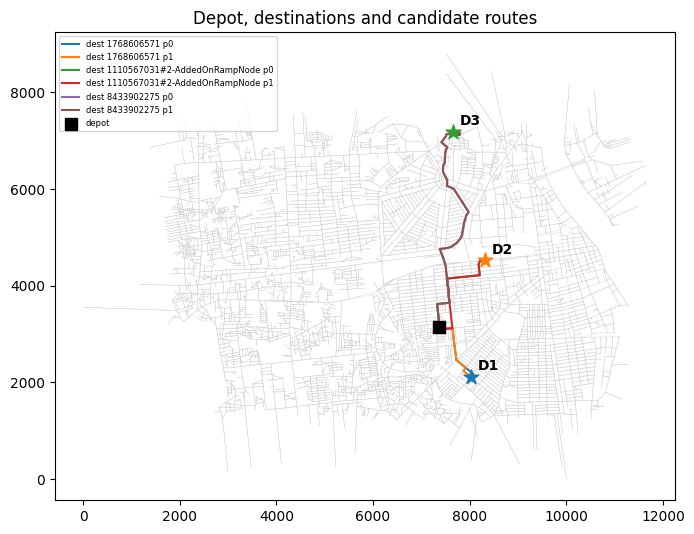

In [101]:
# Optional: visualise depot, destinations and routes
fig, ax = plt.subplots(figsize=(8, 8))
for u, v in G.edges:
    (x1, y1), (x2, y2) = G.nodes[u]["pos"], G.nodes[v]["pos"]
    ax.plot([x1, x2], [y1, y2], color="lightgray", lw=0.3, zorder=1)
for a, route in NODE_PATHS.items():
    xs, ys = zip(*(G.nodes[n]["pos"] for n in route))
    ax.plot(xs, ys, lw=1.5, zorder=2, label=f"dest {a[0]} p{a[1]}")
ax.scatter(*G.nodes[DEPOT_NODE]["pos"], c="black", marker="s", s=80, zorder=3, label="depot")

for i, d in enumerate(DESTINATION_NODES, start=1):
    ax.scatter(*G.nodes[d]["pos"], marker="*", s=120, zorder=3)

    # Add destination label
    x, y = G.nodes[d]["pos"]
    ax.annotate(
        f"D{i}",
        (x, y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold"
    )

ax.set_aspect("equal"); ax.set_title("Depot, destinations and candidate routes")
ax.legend(fontsize=6, loc="best")
plt.show()


## Next step
`paths`, `C_norm`, `S`, `vans` feed directly into the QUBO builder (`build_qubo`) with e.g. `Qv={1: 2, 2: 2, 3: 1}`.

**Thesis notes:** network filtered to vehicle-accessible edges and the largest strongly connected component; routes from Yen's $k$-shortest paths (no $A^*$ heuristic is used); the first `SKIP_HOPS` depot edges are excluded from the overlap count.

In [102]:

def build_qubo(lam_cong=0.2, A=10, B=10):
    """
    Build a QUBO model for multi-van destination assignment
    with congestion-aware candidate path selection.

    Parameters:
        lam_cong: Weight of the congestion objective.
        A: Penalty for not assigning each destination exactly once.
        B: Penalty for assigning multiple destinations to one van.

    Returns:
        Q: QUBO coefficient dictionary.
        variables: List of binary variable tuples.
    """

    # --------------------------------------------------
    # 1. Create binary variables
    # --------------------------------------------------

    variables = [
        (v, d, p)
        for v in vans
        for d, candidate_paths in paths.items()
        for p in candidate_paths
    ]

    # Assign an index to each variable
    var_index = {
        var: i for i, var in enumerate(variables)
    }

    # Initialize QUBO coefficient dictionary
    Q = {}

    def add_term(var1, var2, coefficient):
        """Add a linear or quadratic coefficient to Q."""

        # Ensure consistent variable ordering
        if var_index[var1] > var_index[var2]:
            var1, var2 = var2, var1

        key = (var1, var2)
        Q[key] = Q.get(key, 0) + coefficient

    # --------------------------------------------------
    # 2. Travel cost objective
    # --------------------------------------------------

    # H1 = sum(C_norm[d,p] * x[v,d,p])

    for v, d, p in variables:
        route = (d, p)

        add_term(
            (v, d, p),
            (v, d, p),
            C_norm[route]
        )

    # --------------------------------------------------
    # 3. Congestion objective
    # --------------------------------------------------

    # Only compare routes belonging to different destinations.

    valid_congestion_pairs = [
        (route_pair, overlap)
        for route_pair, overlap in S.items()
        if route_pair[0][0] != route_pair[1][0]
    ]

    # Normalize overlap using only valid route pairs.

    max_overlap = max(
        (overlap for _, overlap in valid_congestion_pairs),
        default=0
    )

    for (route_a, route_b), overlap in valid_congestion_pairs:

        if max_overlap == 0:
            continue

        overlap_norm = overlap / max_overlap

        congestion_cost = lam_cong * overlap_norm

        d1, p1 = route_a
        d2, p2 = route_b

        # Consider every possible pair of vans.
        for v1 in vans:
            for v2 in vans:

                var1 = (v1, d1, p1)
                var2 = (v2, d2, p2)

                add_term(var1, var2, congestion_cost)

    # --------------------------------------------------
    # 4. Destination assignment constraint
    # --------------------------------------------------

    # Each destination must be assigned exactly once.
    #
    # H_A = A * (sum(x) - 1)^2
    #
    # Expanded:
    # H_A = A - A*sum(x) + 2*A*sum(x_i*x_j)
    #
    # The constant A is omitted because it does not
    # affect which solution minimizes the QUBO.

    for d in paths:

        destination_vars = [
            (v, d, p)
            for v in vans
            for p in paths[d]
        ]

        # Linear penalty
        for var in destination_vars:
            add_term(var, var, -A)

        # Quadratic penalty
        for var1, var2 in combinations(destination_vars, 2):
            add_term(var1, var2, 2 * A)

    # --------------------------------------------------
    # 5. Van capacity constraint
    # --------------------------------------------------

    # Each van can serve at most one destination.
    #
    # H_B = B * sum(x_i * x_j)

    for v in vans:

        van_vars = [
            (v, d, p)
            for d in paths
            for p in paths[d]
        ]

        for var1, var2 in combinations(van_vars, 2):
            add_term(var1, var2, B)

    # --------------------------------------------------
    # 6. Create readable destination and variable labels
    # --------------------------------------------------

    destination_labels = {
        d: f"D{i + 1}"
        for i, d in enumerate(DESTINATION_NODES)
    }

    variable_labels = {
        var: f"x{v}_{destination_labels[d]}_P{p + 1}"
        for var in variables
        for v, d, p in [var]
    }

    # --------------------------------------------------
    # 7. Display QUBO model information
    # --------------------------------------------------

    print("========== QUBO MODEL ==========")

    print(f"Number of vans: {len(vans)}")
    print(f"Number of destinations: {len(paths)}")
    print(f"Number of binary variables: {len(variables)}")

    print("\nDestination labels:")

    for d, label in destination_labels.items():
        print(f"  {label}")

    print("\nObjective weights:")
    print(f"  Congestion weight: {lam_cong}")
    print(f"  Destination penalty A: {A}")
    print(f"  Van capacity penalty B: {B}")

    print(f"\nNumber of QUBO coefficients: {len(Q)}")

    # --------------------------------------------------
    # 8. Display binary variables
    # --------------------------------------------------

    print("\n========== BINARY VARIABLES ==========")

    for var in variables:
        print(f"{variable_labels[var]} ∈ {{0, 1}}")

    # --------------------------------------------------
    # 9. Display QUBO coefficients
    # --------------------------------------------------

    print("\n========== QUBO COEFFICIENTS ==========")

    for (var1, var2), coefficient in Q.items():

        name1 = variable_labels[var1]
        name2 = variable_labels[var2]

        print(
            f"Q[{name1}, {name2}] = {coefficient:.4f}"
        )


    return Q, variables


In [103]:
Q, variables = build_qubo()


========== QUBO MODEL ==========
Number of vans: 3
Number of destinations: 3
Number of binary variables: 18

Destination labels:
  D1
  D2
  D3

Objective weights:
  Congestion weight: 0.2
  Destination penalty A: 10
  Van capacity penalty B: 10

Number of QUBO coefficients: 171

========== BINARY VARIABLES ==========
x1_D1_P1 ∈ {0, 1}
x1_D1_P2 ∈ {0, 1}
x1_D2_P1 ∈ {0, 1}
x1_D2_P2 ∈ {0, 1}
x1_D3_P1 ∈ {0, 1}
x1_D3_P2 ∈ {0, 1}
x2_D1_P1 ∈ {0, 1}
x2_D1_P2 ∈ {0, 1}
x2_D2_P1 ∈ {0, 1}
x2_D2_P2 ∈ {0, 1}
x2_D3_P1 ∈ {0, 1}
x2_D3_P2 ∈ {0, 1}
x3_D1_P1 ∈ {0, 1}
x3_D1_P2 ∈ {0, 1}
x3_D2_P1 ∈ {0, 1}
x3_D2_P2 ∈ {0, 1}
x3_D3_P1 ∈ {0, 1}
x3_D3_P2 ∈ {0, 1}

========== QUBO COEFFICIENTS ==========
Q[x1_D1_P1, x1_D1_P1] = -9.7523
Q[x1_D1_P2, x1_D1_P2] = -9.7220
Q[x1_D2_P1, x1_D2_P1] = -9.6017
Q[x1_D2_P2, x1_D2_P2] = -9.5861
Q[x1_D3_P1, x1_D3_P1] = -9.0001
Q[x1_D3_P2, x1_D3_P2] = -9.0000
Q[x2_D1_P1, x2_D1_P1] = -9.7523
Q[x2_D1_P2, x2_D1_P2] = -9.7220
Q[x2_D2_P1, x2_D2_P1] = -9.6017
Q[x2_D2_P2, x2_D2_P2] = -9.